In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/processed/cleaned_data.csv')

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df.head()

C:\Users\Faisal\AppData\Local\Temp\ipykernel_16948\35972601.py:4: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/processed/cleaned_data.csv')


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [2]:
df.shape

(524878, 9)

In [3]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue'],
      dtype='object')

In [4]:
df['InvoiceDate'].min(), df['InvoiceDate'].max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:50:00'))

In [5]:
cutoff_date = pd.Timestamp('2011-09-10')

cutoff_date

Timestamp('2011-09-10 00:00:00')

In [6]:
past_data = df[df['InvoiceDate'] < cutoff_date].copy()

future_data = df[
    (df['InvoiceDate'] >= cutoff_date) &
    (df['InvoiceDate'] < cutoff_date + pd.Timedelta(days=90))
].copy()

print("Past data:", past_data.shape)
print("Future data:", future_data.shape)

Past data: (323645, 9)
Future data: (199615, 9)


In [7]:
future_customers = future_data['CustomerID'].dropna().unique()

len(future_customers)

2886

In [8]:
customer_data = past_data.dropna(subset=['CustomerID']).groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (cutoff_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Unique_Products=('StockCode', 'nunique')
).reset_index()

In [9]:
customer_data['Churn'] = (
    ~customer_data['CustomerID'].isin(future_customers)
).astype(int)

In [10]:
customer_data['Churn'].value_counts()

Churn
0    1919
1    1451
Name: count, dtype: int64

In [11]:
customer_data.shape

(3370, 7)

In [12]:
customer_data.head()

,CustomerID,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,Churn
0,12346.0,234,1,77183.60,74215,1,1
1,12347.0,38,5,2790.86,1590,82,0
2,12348.0,157,3,1487.24,2124,22,0
3,12350.0,219,1,334.40,197,17,1
4,12352.0,171,5,1561.81,254,26,0


In [13]:
customer_data.isnull().sum()

CustomerID         0
Recency            0
Frequency          0
Monetary           0
Total_Quantity     0
Unique_Products    0
Churn              0
dtype: int64

In [14]:
customer_features = past_data.dropna(subset=['CustomerID']).groupby('CustomerID').agg(
    First_Purchase=('InvoiceDate', 'min'),
    Last_Purchase=('InvoiceDate', 'max'),
    Purchase_Months=('InvoiceDate', lambda x: x.dt.to_period('M').nunique())
).reset_index()

customer_features['Customer_Lifetime'] = (
    customer_features['Last_Purchase'] -
    customer_features['First_Purchase']
).dt.days

customer_features = customer_features.merge(
    customer_data[['CustomerID', 'Frequency', 'Monetary']],
    on='CustomerID',
    how='left'
)

customer_features['Avg_Order_Value'] = (
    customer_features['Monetary'] /
    customer_features['Frequency']
)

customer_features['Average_Days_Between_Orders'] = np.where(
    customer_features['Frequency'] > 1,
    customer_features['Customer_Lifetime'] /
    (customer_features['Frequency'] - 1),
    0
)

customer_features.head()

,CustomerID,First_Purchase,Last_Purchase,Purchase_Months,Customer_Lifetime,Frequency,Monetary,Avg_Order_Value,Average_Days_Between_Orders
0,12346.0,2011-01-18 10:01:00,2011-01-18 10:01:00,1,0,1,77183.60,77183.600000,0.00
1,12347.0,2010-12-07 14:57:00,2011-08-02 08:48:00,5,237,5,2790.86,558.172000,59.25
2,12348.0,2010-12-16 19:09:00,2011-04-05 10:47:00,3,109,3,1487.24,495.746667,54.50
3,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00,1,0,1,334.40,334.400000,0.00
4,12352.0,2011-02-16 12:33:00,2011-03-22 16:08:00,2,34,5,1561.81,312.362000,8.50


In [15]:
customer_features.shape

(3370, 9)

In [16]:
customer_features.describe()

,CustomerID,First_Purchase,Last_Purchase,Purchase_Months,Customer_Lifetime,Frequency,Monetary,Avg_Order_Value,Average_Days_Between_Orders
count,3370.000000,3370,3370,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000
mean,15276.122849,2011-03-11 15:19:38.154302720,2011-06-07 13:03:43.673590528,2.535608,87.621958,3.533234,1615.127193,397.246684,35.183686
min,12346.000000,2010-12-01 08:26:00,2010-12-01 09:53:00,1.000000,0.000000,1.000000,2.900000,2.900000,0.000000
25%,13786.250000,2010-12-19 15:00:15,2011-04-11 21:37:45,1.000000,0.000000,1.000000,264.640000,168.302500,0.000000
50%,15234.500000,2011-03-01 09:15:30,2011-06-28 11:50:00,2.000000,54.000000,2.000000,563.210000,283.077000,20.358974
75%,16765.750000,2011-05-10 12:25:45,2011-08-15 13:49:45,3.000000,170.000000,4.000000,1388.937500,412.411000,53.650000
max,18287.000000,2011-09-09 14:47:00,2011-09-09 15:53:00,10.000000,282.000000,132.000000,178302.620000,77183.600000,270.000000
std,1725.580817,NaN,NaN,2.061983,95.290059,5.788361,6148.013905,1422.620426,45.964214


In [17]:
model_data = customer_data.merge(
    customer_features[
        [
            'CustomerID',
            'Purchase_Months',
            'Customer_Lifetime',
            'Avg_Order_Value',
            'Average_Days_Between_Orders'
        ]
    ],
    on='CustomerID',
    how='left'
)

model_data.head()

,CustomerID,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,Churn,Purchase_Months,Customer_Lifetime,Avg_Order_Value,Average_Days_Between_Orders
0,12346.0,234,1,77183.60,74215,1,1,1,0,77183.600000,0.00
1,12347.0,38,5,2790.86,1590,82,0,5,237,558.172000,59.25
2,12348.0,157,3,1487.24,2124,22,0,3,109,495.746667,54.50
3,12350.0,219,1,334.40,197,17,1,1,0,334.400000,0.00
4,12352.0,171,5,1561.81,254,26,0,2,34,312.362000,8.50


In [18]:
model_data.shape

(3370, 11)

In [19]:
model_data.columns.tolist()

['CustomerID',
 'Recency',
 'Frequency',
 'Monetary',
 'Total_Quantity',
 'Unique_Products',
 'Churn',
 'Purchase_Months',
 'Customer_Lifetime',
 'Avg_Order_Value',
 'Average_Days_Between_Orders']

In [20]:
features = [
    'Recency',
    'Frequency',
    'Monetary',
    'Total_Quantity',
    'Unique_Products',
    'Purchase_Months',
    'Customer_Lifetime',
    'Avg_Order_Value',
    'Average_Days_Between_Orders'
]

X = model_data[features]
y = model_data['Churn']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3370, 9)
y shape: (3370,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (2696, 9)
X_test_scaled: (674, 9)


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        X_train_scaled,
        X_test_scaled
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        X_train,
        X_test
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        X_train,
        X_test
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
        X_train,
        X_test
    ),
    "Extra Trees": (
        ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        X_train,
        X_test
    ),
    "AdaBoost": (
        AdaBoostClassifier(n_estimators=100, random_state=42),
        X_train,
        X_test
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=42),
        X_train,
        X_test
    ),
    "KNN": (
        KNeighborsClassifier(n_neighbors=5),
        X_train_scaled,
        X_test_scaled
    ),
    "Naive Bayes": (
        GaussianNB(),
        X_train_scaled,
        X_test_scaled
    ),
    "SVM": (
        SVC(probability=True, random_state=42),
        X_train_scaled,
        X_test_scaled
    )
}

results = []

for name, (model, train_data, test_data) in models.items():
    model.fit(train_data, y_train)

    predictions = model.predict(test_data)
    probabilities = model.predict_proba(test_data)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Naive Bayes,0.627596,0.542299,0.862069,0.665779,0.720133
1,AdaBoost,0.673591,0.598315,0.734483,0.659443,0.725530
2,Logistic Regression,0.670623,0.608974,0.655172,0.631229,0.731403
3,SVM,0.666172,0.605178,0.644828,0.624374,0.713479
4,Gradient Boosting,0.651335,0.590164,0.620690,0.605042,0.714781
5,Hist Gradient Boosting,0.658754,0.607143,0.586207,0.596491,0.708971
6,Random Forest,0.652819,0.597222,0.593103,0.595156,0.704643
7,KNN,0.645401,0.589474,0.579310,0.584348,0.698042
8,Extra Trees,0.646884,0.595588,0.558621,0.576512,0.696628
9,Decision Tree,0.617211,0.555172,0.555172,0.555172,0.609617


In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    random_state=42
)

param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}

grid_search = GridSearchCV(
    estimator=adaboost,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.01, 'n_estimators': 50}
Best CV F1: 0.6852789825131561


In [39]:
best_adaboost = grid_search.best_estimator_

y_pred_final = best_adaboost.predict(X_test)
y_prob_final = best_adaboost.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall   :", recall_score(y_test, y_pred_final))
print("F1 Score :", f1_score(y_test, y_pred_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Accuracy : 0.6409495548961425
Precision: 0.5560747663551402
Recall   : 0.8206896551724138
F1 Score : 0.6629526462395543
ROC-AUC  : 0.688415948275862

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.51      0.62       384
           1       0.56      0.82      0.66       290

    accuracy                           0.64       674
   macro avg       0.67      0.66      0.64       674
weighted avg       0.69      0.64      0.64       674



In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_final >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.20,0.556075,0.82069,0.662953
1,0.25,0.556075,0.82069,0.662953
2,0.30,0.556075,0.82069,0.662953
3,0.35,0.556075,0.82069,0.662953
4,0.40,0.556075,0.82069,0.662953
5,0.45,0.556075,0.82069,0.662953
6,0.50,0.556075,0.82069,0.662953
7,0.55,0.556075,0.82069,0.662953
8,0.60,0.556075,0.82069,0.662953
9,0.65,0.556075,0.82069,0.662953


In [41]:
print("Minimum probability:", y_prob_final.min())
print("Maximum probability:", y_prob_final.max())

print("\nUnique probability values:")
print(np.unique(y_prob_final))

print("\nNumber of unique probabilities:", len(np.unique(y_prob_final)))


Minimum probability: 0.11920292202211755
Maximum probability: 0.8807970779778823

Unique probability values:
[0.11920292 0.16066687 0.83933313 0.88079708]

Number of unique probabilities: 4


[[194 190]
 [ 52 238]]


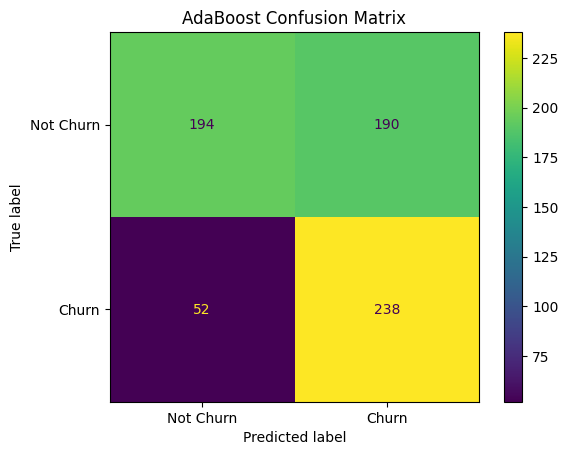

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_final)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Churn', 'Churn']
).plot()

plt.title('AdaBoost Confusion Matrix')
plt.show()

In [43]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': best_adaboost.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
5,Purchase_Months,0.913319
6,Customer_Lifetime,0.086681
0,Recency,0.000000
1,Frequency,0.000000
2,Monetary,0.000000
4,Unique_Products,0.000000
3,Total_Quantity,0.000000
7,Avg_Order_Value,0.000000
8,Average_Days_Between_Orders,0.000000


In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    random_state=42
)

param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.05, 0.1, 0.5, 1.0]
}

grid_search = GridSearchCV(
    estimator=adaboost,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.05, 'n_estimators': 50}
Best CV F1: 0.6605500288597356


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'penalty': ['l2']
}

grid_search_lr = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_search_lr.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search_lr.best_params_)
print("Best CV F1:", grid_search_lr.best_score_)


Best Parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV F1: 0.6468974868381544


C:\Users\Faisal\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [47]:
final_model = grid_search.best_estimator_

y_pred_final = final_model.predict(X_test)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

print("Final AdaBoost Model")
print("--------------------")
print("Parameters:", grid_search.best_params_)
print("CV F1:", grid_search.best_score_)

print("\nTest Performance")
print("--------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall   :", recall_score(y_test, y_pred_final))
print("F1 Score :", f1_score(y_test, y_pred_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_final))

Final AdaBoost Model
--------------------
Parameters: {'learning_rate': 0.05, 'n_estimators': 50}
CV F1: 0.6605500288597356

Test Performance
--------------------
Accuracy : 0.6543026706231454
Precision: 0.5721518987341773
Recall   : 0.7793103448275862
F1 Score : 0.6598540145985401
ROC-AUC  : 0.7262706537356323


In [48]:
import joblib

joblib.dump(
    final_model,
    '../models/churn_adaboost.pkl'
)

joblib.dump(
    features,
    '../models/churn_features.pkl'
)

print("Model saved successfully!")
print("Features saved successfully!")

Model saved successfully!
Features saved successfully!


In [49]:
import os

print(os.path.exists('../models/churn_adaboost.pkl'))
print(os.path.exists('../models/churn_features.pkl'))

True
True
